# Đánh giá hiệu năng và độ ổn định của các phương pháp phân cụm sâu

**Câu hỏi:** phương pháp ra đời sau thay đổi điều gì, và thay đổi đó có giúp phân cụm tốt hơn không?

Bốn mốc: **DEC (2016) → IDEC (2017) → DECRA (2024) → DCSS (2026)**.
Cùng bộ Digits, mỗi phương pháp 5 lần khởi tạo ngẫu nhiên, tổng cộng **20 lượt chạy chính**.
BRB (2025) được đối chiếu bằng số liệu bài báo, chưa chạy trong nhóm bốn phương pháp này.

Các triển khai là bản chuyển thể bằng NumPy, dùng chung một kiến trúc mạng nhỏ.
Chưa chạy đúng toàn bộ kiến trúc và môi trường của tác giả; kết luận giới hạn trong cấu hình ở đây.

**Thứ tự đọc:** dữ liệu và cách so sánh → thay đổi phương pháp → kết quả → giải thích → bằng chứng bài báo → kết luận.
Notebook đọc kết quả đã lưu; ô huấn luyện mới nằm cuối và mặc định tắt.

In [1]:
from pathlib import Path
from datetime import datetime
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown, HTML

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif not (ROOT / 'run_demo.py').is_file() and (ROOT / 'Deep_Clustering_Demo').is_dir():
    ROOT = ROOT / 'Deep_Clustering_Demo'
assert (ROOT / 'run_demo.py').is_file(), 'Mở notebook từ thư mục dự án.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / 'results/timeline_20261013'
config = json.loads((OUT / 'config.json').read_text(encoding='utf-8'))
METHODS = config['methods']
assert METHODS == ['DEC', 'IDEC', 'DECRA', 'DCSS'], 'Cần kết quả của đúng bốn phương pháp.'
runs = pd.read_csv(OUT / 'runs.csv')
summary = pd.read_csv(OUT / 'summary.csv')
expected = {(m, int(s)) for m in METHODS for s in config['seeds']}
assert {(r.method, int(r.seed)) for r in runs.itertuples()} == expected
assert len(runs) == len(expected) and len(summary) == len(METHODS)
verification = json.loads((OUT / 'verification.json').read_text(encoding='utf-8'))
assert verification['status'] == 'passed' and verification['runs_verified'] == len(runs)
assert verification['same_training_data_all_methods']

def vn(value, digits=2):
    return f'{float(value):.{digits}f}'.replace('.', ',')

def mean_std(row, metric, scale=100, digits=2):
    return f'{vn(row[metric + "_mean"] * scale, digits)} ± {vn(row[metric + "_std"] * scale, digits)}'

def show_table(frame):
    display(HTML(frame.to_html(index=False, escape=True, border=0)))

def picture(name, folder=OUT):
    display(Image(filename=str(folder / name), width=950))

def quality_table(frame, name_column='method'):
    return pd.DataFrame([{
        'Phương pháp': r[name_column], 'Số seed': int(r['n_runs']),
        'ACC (%)': mean_std(r, 'acc'), 'NMI (%)': mean_std(r, 'nmi'), 'ARI (%)': mean_std(r, 'ari'),
    } for _, r in frame.iterrows()])

print(f'Đang xem {len(runs)} lượt đã lưu: {", ".join(METHODS)}; {len(config["seeds"])} seed.')

Đang xem 20 lượt đã lưu: DEC, IDEC, DECRA, DCSS; 5 seed.


## 1. Dữ liệu lấy từ đâu, so sánh thế nào?

Nguồn: [scikit-learn load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html),
bắt nguồn từ [UCI Optical Recognition of Handwritten Digits](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).
Bản dùng ở đây có **1.797 ảnh 8×8, 64 đặc trưng, 10 lớp chữ số**, khác bộ UCI đầy đủ 5.620 mẫu.
Pixel được chia cho 16 để vào [0,1]. Nhãn thật chỉ dùng chấm kết quả, không dùng huấn luyện hoặc chọn tham số.

**Seed** là mã khởi tạo ngẫu nhiên. Mỗi seed học mạng lại từ đầu; bốn phương pháp nhận cùng trọng số
tiền huấn luyện và tâm K-means ban đầu trong seed đó. **Epoch** là một lượt đi qua dữ liệu.
Toàn bộ X được học và phân cụm; chưa có tập chưa thấy để đo khả năng tổng quát hóa.

Nội dung,Thiết lập
Dữ liệu,1797 ảnh; 64 đặc trưng; 10 cụm
Miền giá trị sau chuẩn hóa,"[0, 1]"
Kiến trúc mạng,64 → 64 → 32 → 10 → 32 → 64 → 64
Tiền huấn luyện mạng,"120 epoch, học tái tạo dữ liệu"
Huấn luyện phân cụm,60 epoch mỗi phương pháp
Nhóm mẫu mỗi lần cập nhật,128
Tối ưu,"Adam, tốc độ học 0,001"
Khởi tạo tâm,"K-means, 20 khởi tạo"
Làm mới mục tiêu P,"Mỗi 5 epoch; DEC, IDEC, DECRA"
Tổng lượt chính,4 phương pháp × 5 seed = 20 lượt


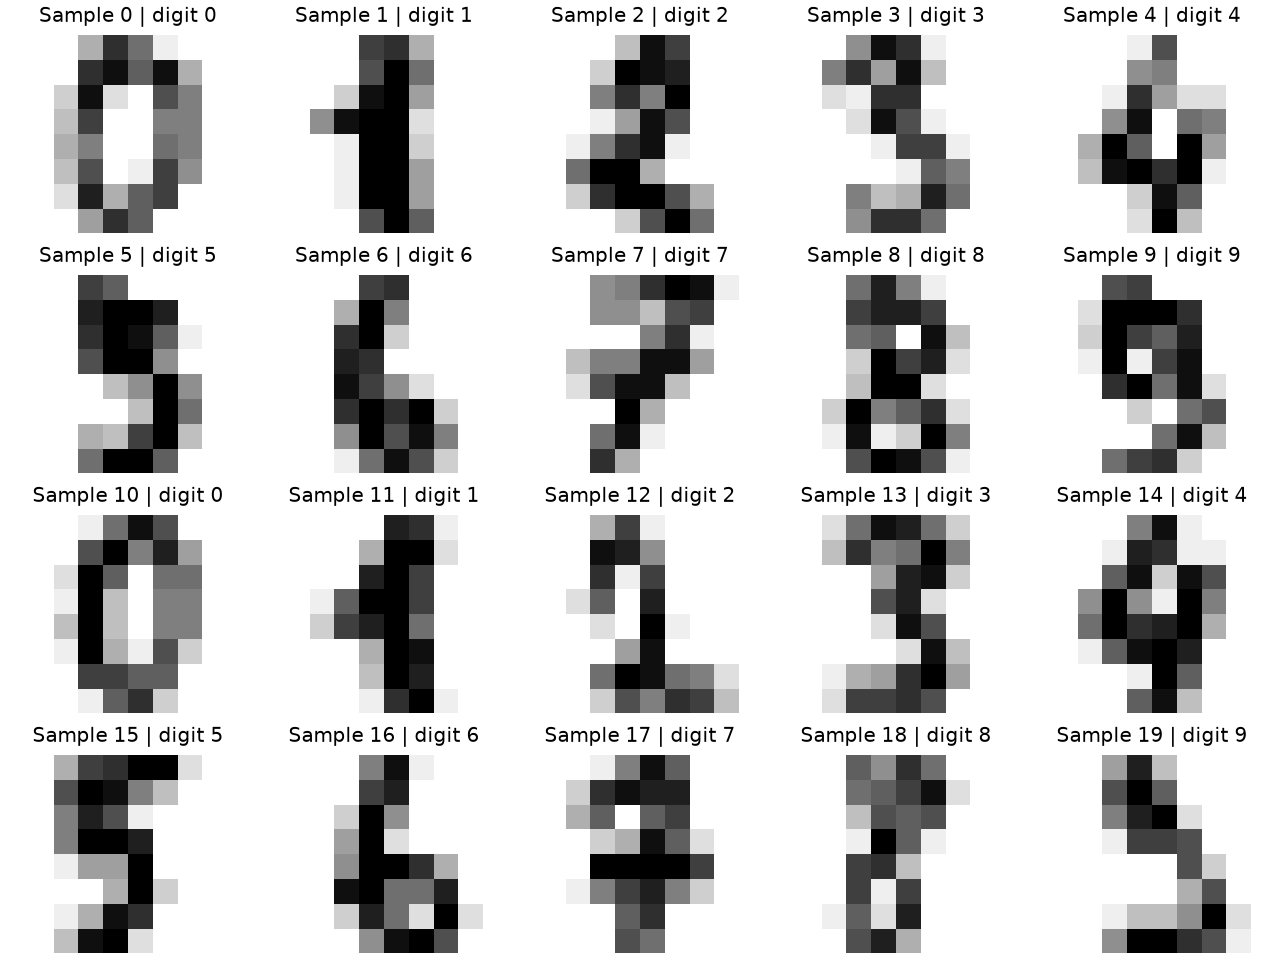

In [2]:
data_path = Path(config['data'])
if not data_path.is_absolute():
    data_path = ROOT / data_path
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == config['sha256_data']
indices = np.load(OUT / 'sample_indices.npy', allow_pickle=False)
with np.load(data_path, allow_pickle=False) as bundle:
    X, y = bundle['X'][indices].astype(np.float64), bundle['y'][indices]
assert hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest() == config['sha256_training_X']
show_table(pd.DataFrame([
    ['Dữ liệu', f'{len(X)} ảnh; {X.shape[1]} đặc trưng; {config["clusters"]} cụm'],
    ['Miền giá trị sau chuẩn hóa', f'[{vn(X.min(), 0)}, {vn(X.max(), 0)}]'],
    ['Kiến trúc mạng', ' → '.join(map(str, config['architecture']))],
    ['Tiền huấn luyện mạng', f'{config["pretrain_epochs"]} epoch, học tái tạo dữ liệu'],
    ['Huấn luyện phân cụm', f'{config["cluster_epochs"]} epoch mỗi phương pháp'],
    ['Nhóm mẫu mỗi lần cập nhật', config['batch_size']],
    ['Tối ưu', f'Adam, tốc độ học {vn(config["learning_rate"], 3)}'],
    ['Khởi tạo tâm', f'K-means, {config["n_init"]} khởi tạo'],
    ['Làm mới mục tiêu P', f'Mỗi {config["target_interval"]} epoch; DEC, IDEC, DECRA'],
    ['Tổng lượt chính', f'{len(METHODS)} phương pháp × {len(config["seeds"])} seed = {len(runs)} lượt'],
    ['Vai trò của nhãn', 'Chỉ đánh giá sau huấn luyện'],
], columns=['Nội dung', 'Thiết lập']))
picture('sample_images.png')

## 2. Phương pháp sau thay đổi điều gì?

| Mốc | Hạn chế muốn xử lý | Thay đổi chính | Điều cần kiểm tra |
|---|---|---|---|
| DEC 2016 | Đặc trưng đầu vào chưa phù hợp phân cụm | Học biểu diễn và tâm bằng mục tiêu tự tạo | Điểm số và độ nhạy khởi tạo |
| IDEC 2017 | Chỉ học cụm có thể làm mất cấu trúc dữ liệu | Thêm tái tạo ảnh, giữ bộ giải mã khi học cụm | Có tăng chất lượng, giảm biến động so với DEC không? |
| DECRA 2024 | Tái tạo quá chặt có thể giữ thông tin không phục vụ cụm | Thêm nhánh biến đổi biểu diễn và nhất quán hai đường giải mã | Lợi ích có bù tham số và yêu cầu học tăng thêm không? |
| DCSS 2026 | Cần cụm vừa gọn vừa tách biệt | Soft silhouette, entropy và xác suất RBF | Có nhạy với thang đo biểu diễn và độ rộng RBF không? |

**Autoencoder** gồm bộ mã hóa nén ảnh thành biểu diễn 10 chiều và bộ giải mã tái tạo ảnh.
**RBF** cho điểm gần tâm theo khoảng cách; σ là độ rộng quyết định khoảng ảnh hưởng của tâm.
**Soft silhouette** đo độ gọn và tách biệt khi mẫu có xác suất thuộc nhiều cụm.
**Entropy** đo độ phân tán của xác suất gán cụm; giá trị lớn thường tương ứng gán ít chắc chắn hơn.

Nguồn bài và mã tác giả:

- DEC: [ICML 2016](https://proceedings.mlr.press/v48/xieb16.html), [mã](https://github.com/piiswrong/dec).
- IDEC: [IJCAI 2017](https://www.ijcai.org/proceedings/2017/243), [mã](https://github.com/XifengGuo/IDEC).
- DECRA: [Neural Processing Letters 2024](https://doi.org/10.1007/s11063-024-11586-0), [mã](https://github.com/lml-mengli/DECRA).
- DCSS: [Machine Learning 2026](https://doi.org/10.1007/s10994-026-07026-w), [mã](https://github.com/gvardakas/Soft-Silhouette).

DCSS được chọn cho mốc 2026 vì cùng họ autoencoder, có mã công khai và bài gốc so sánh DEC/IDEC/DECRA.
Mũi tên thể hiện thời gian; không có nghĩa mọi bài kế thừa trực tiếp hoặc bài mới hơn luôn tốt hơn.

## 3. Code minh họa cơ chế học

**Q** là xác suất gán mẫu vào các cụm. **P** tăng trọng số các gán tự tin, tạo mục tiêu cho DEC/IDEC/DECRA.
DEC giảm sai khác giữa P và Q, đo bằng **KL**. IDEC còn giảm lỗi tái tạo, đo bằng **MSE**.
Ô dưới dùng trọng số tiền huấn luyện của seed đầu, chưa cập nhật mô hình, không truyền nhãn y vào phép tính.
Code đầy đủ: [DEC/IDEC](../src/models.py), [DECRA](../src/decra.py), [DCSS](../src/dcss.py).

In [3]:
from src.models import (Autoencoder, assignments, target_distribution,
                        kl_loss_and_gradients, reconstruct_loss_and_gradient)
from src.decra import initialize_adaptive_layer, decra_loss_and_gradients
from src.dcss import dcss_loss_and_gradients

seed = config['seeds'][0]
model = Autoencoder(X.shape[1], config['latent_dim'], seed)
with np.load(OUT / 'models' / f'pretrain_seed{seed}.npz', allow_pickle=False) as saved:
    model.params = {k: saved[k].copy() for k in saved.files}
with np.load(OUT / 'models' / f'initialization_seed{seed}.npz', allow_pickle=False) as saved:
    centers = saved['centers'].copy()
Q = assignments(model.encode(X), centers)
P = target_distribution(Q)
assert np.allclose(Q.sum(1), 1) and np.allclose(P.sum(1), 1)
show_table(pd.DataFrame({
    'Mẫu': np.arange(1, 6),
    'Xác suất lớn nhất trong Q': [vn(v, 3) for v in Q[:5].max(1)],
    'Xác suất lớn nhất trong P': [vn(v, 3) for v in P[:5].max(1)],
}))
print('P được tạo từ Q; nhãn thật không tham gia phép tính.')

Mẫu,Xác suất lớn nhất trong Q,Xác suất lớn nhất trong P
1,"0,489","0,871"
2,"0,298","0,596"
3,"0,205","0,321"
4,"0,311","0,593"
5,"0,240","0,454"


P được tạo từ Q; nhãn thật không tham gia phép tính.


### 3.1. Thành phần được tối ưu

**E** là MSE tái tạo, **C** là MSE giữa hai đường giải mã, **Kₙ** là KL trung bình theo mẫu.
Công thức dưới mô tả **bản code đang so sánh**, với 10 cụm:

| Phương pháp | Hàm mất mát trong bản chuyển thể |
|---|---|
| DEC | Kₙ |
| IDEC | E + 0,1Kₙ |
| DECRA | 2E + 0,6C + 0,1Kₙ/10 |
| DCSS | E + 0,01 × (1 − soft silhouette) + 0,01 × entropy (bit, log₂) |

Mã DECRA công khai dùng biến đổi affine (tuyến tính cộng hệ số chệch) và hai đường giải mã,
khác phép cộng residual (cộng lại biểu diễn ban đầu) trong bài.
Bản đang chạy theo mã, dùng tiền huấn luyện mạng thường.
DCSS theo mã công khai: σ=1; hệ số điều chỉnh xác suất (temperature) bằng 0,25;
chuẩn hóa soft silhouette khác phương trình trong bài.
Vì vậy, không coi các kết quả này là tái hiện toàn bộ mô hình nguyên gốc.

Ô dưới tính loss trên cùng nhóm mẫu ban đầu, không cập nhật trọng số.
**Không xếp hạng phương pháp bằng loss tổng vì công thức và thang đo khác nhau.**

In [4]:
batch = X[:config['batch_size']]
target = P[:len(batch)]
z, reconstruction, _ = model.forward(batch)
E, _ = reconstruct_loss_and_gradient(reconstruction, batch)
K_n, _, _ = kl_loss_and_gradients(z, centers, target)
decra_model = model.clone()
initialize_adaptive_layer(decra_model, seed)
dc, _, _ = decra_loss_and_gradients(
    decra_model, batch, centers, target, gamma=config['decra_gamma'],
    reconstruction_weight=config['decra_reconstruction_weight'],
    consistency_weight=config['decra_consistency_weight'], kl_reduction=config['decra_kl_reduction'])
dcss_model = model.clone()
dcss_model.params['log_sigmas'] = np.zeros(config['clusters'])
ds, _, _ = dcss_loss_and_gradients(
    dcss_model, batch, centers, silhouette_weight=config['dcss_silhouette_weight'],
    entropy_weight=config['dcss_entropy_weight'], temperature=config['dcss_temperature'],
    distance_normalization=config['dcss_distance_normalization'])
show_table(pd.DataFrame([
    ['DEC', f'KL = {vn(K_n, 5)}', vn(K_n, 5)],
    ['IDEC', f'MSE = {vn(E, 5)}; KL = {vn(K_n, 5)}', vn(E + config['gamma']*K_n, 5)],
    ['DECRA', f'MSE = {vn(dc["reconstruction"], 5)}; nhất quán = {vn(dc["consistency"], 5)}; KL/10 = {vn(dc["clustering"], 5)}', vn(dc['total'], 5)],
    ['DCSS', f'MSE = {vn(ds["reconstruction"], 5)}; soft silhouette = {vn(ds["soft_silhouette"], 5)}; entropy = {vn(ds["entropy_bits"], 5)}', vn(ds['total'], 5)],
], columns=['Phương pháp', 'Thành phần trước khi học cụm', 'Loss tổng']))

Phương pháp,Thành phần trước khi học cụm,Loss tổng
DEC,"KL = 0,16321","0,16321"
IDEC,"MSE = 0,01254; KL = 0,16321","0,02886"
DECRA,"MSE = 0,01254; nhất quán = 0,13645; KL/10 = 0,01632","0,10859"
DCSS,"MSE = 0,01254; soft silhouette = -0,00527; entropy = 3,31974","0,05579"


### 3.2. Theo dõi quá trình học

Mỗi phương pháp cập nhật theo nhóm 128 mẫu và học cụm trong 60 epoch.
DEC/IDEC/DECRA tính lại P mỗi 5 epoch; DCSS không dùng P.
Loss cho biết quá trình tối ưu của từng phương pháp; phần sau dùng ACC/NMI/ARI để đánh giá chất lượng.

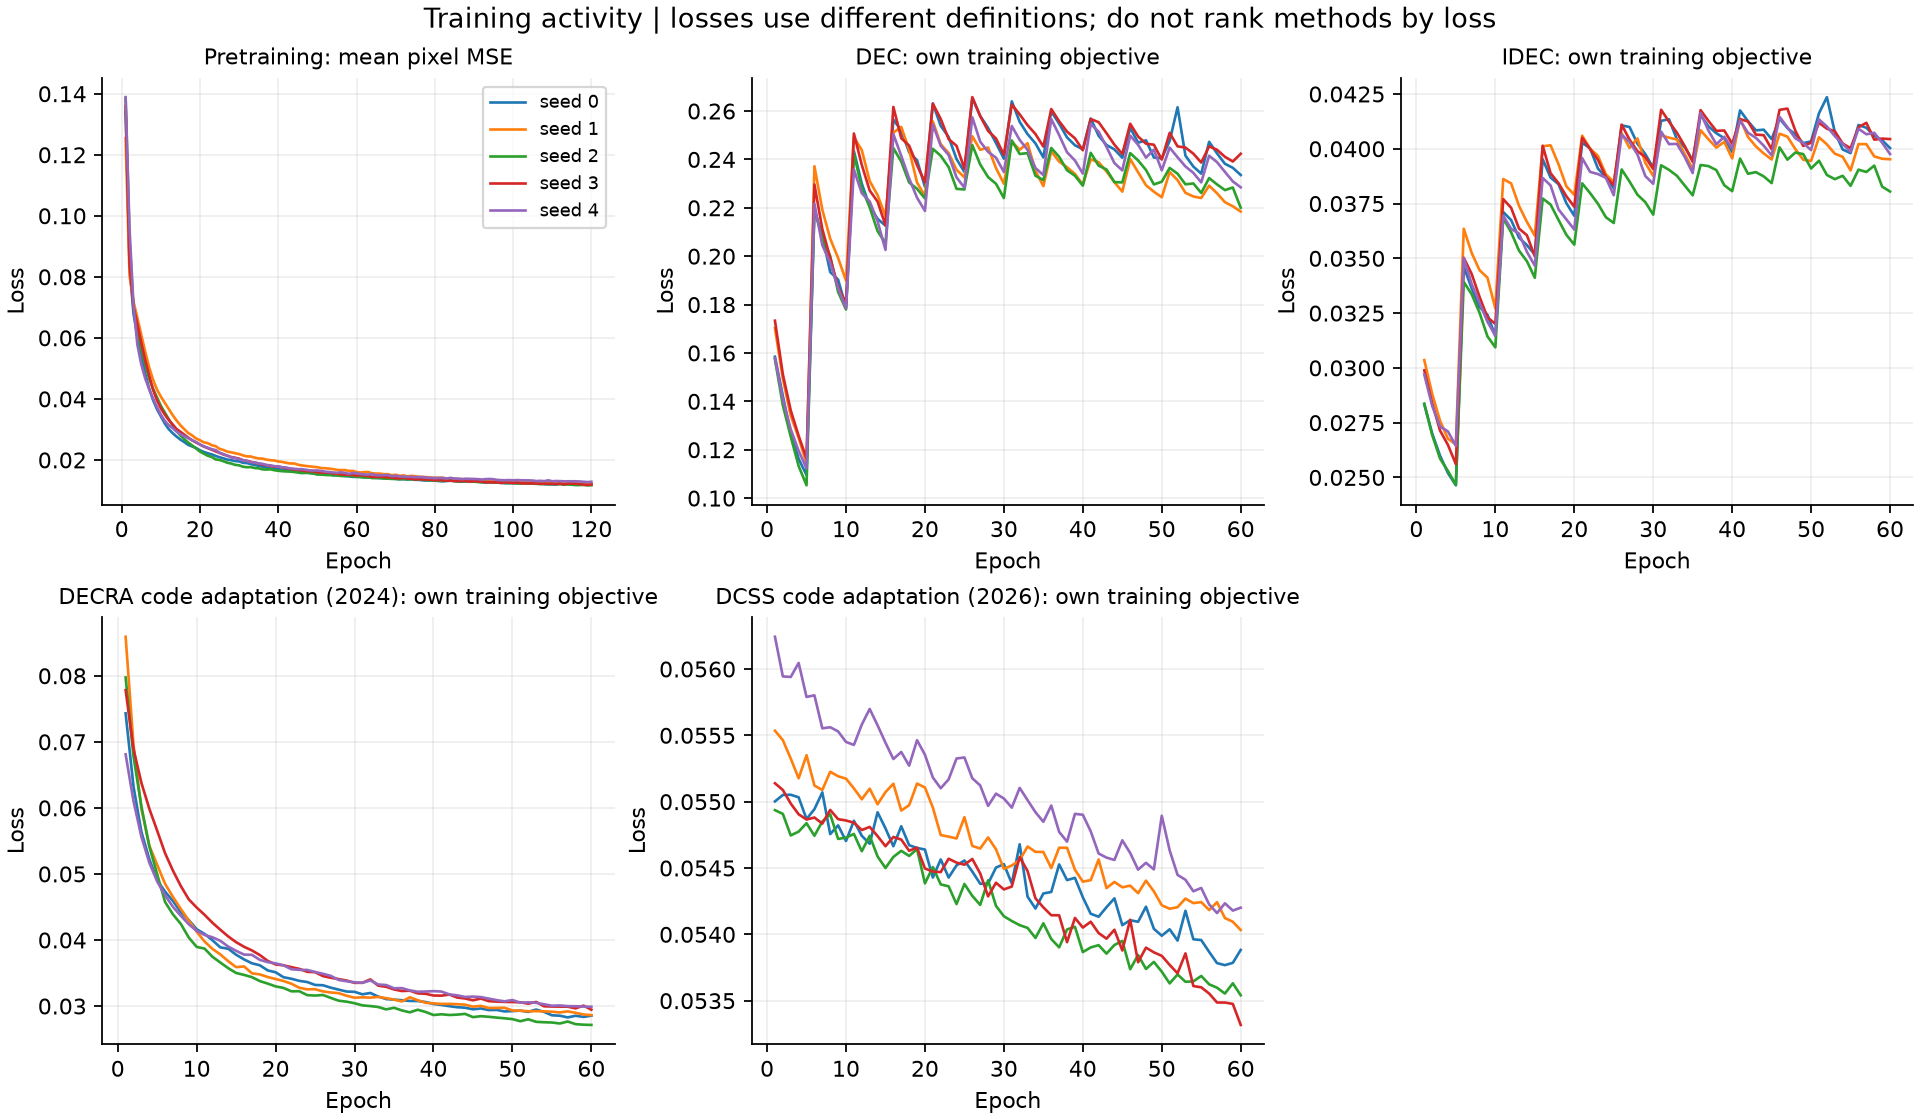

In [5]:
picture('loss_curves.png')

## 4. Kết quả chính: chất lượng, độ ổn định và thời gian

- **ACC:** tỷ lệ đúng sau khi ghép số hiệu cụm với nhãn lớp; cao hơn tốt hơn.
- **NMI:** thông tin chung giữa phân hoạch và nhãn; dùng chuẩn hóa theo trung bình số học.
- **ARI:** đồng thuận giữa các cặp mẫu, đã trừ ảnh hưởng của trùng hợp ngẫu nhiên.
- **Trung bình ± độ lệch chuẩn:** điểm trung bình và biến động qua 5 seed; khác sai số chuẩn SE.
- **ARI giữa seed:** mức giống nhau giữa các phân hoạch của những lần chạy khác nhau.

ACC/NMI/ARI với nhãn được nhân 100 và ghi (%); ARI giữa seed giữ thang đo gốc.
Không gọi phương pháp ổn định hơn chỉ vì điểm ít biến động; nó còn cần đạt chất lượng tốt.

Phương pháp,Số seed,ACC (%),NMI (%),ARI (%)
DEC,5,"74,32 ± 8,34","73,65 ± 4,88","62,70 ± 8,04"
IDEC,5,"74,50 ± 8,07","73,53 ± 4,66","62,49 ± 8,02"
DECRA,5,"70,40 ± 7,36","67,10 ± 3,99","56,76 ± 5,97"
DCSS,5,"51,89 ± 12,51","49,34 ± 12,37","26,23 ± 22,23"


Phương pháp,ARI giữa seed,Thời gian (giây),Số cặp seed
DEC,"0,6504 ± 0,0631","7,92 ± 1,05",10
IDEC,"0,6616 ± 0,0606","8,30 ± 1,40",10
DECRA,"0,5855 ± 0,0578","10,35 ± 0,86",10
DCSS,"0,2018 ± 0,1313","10,82 ± 1,18",10


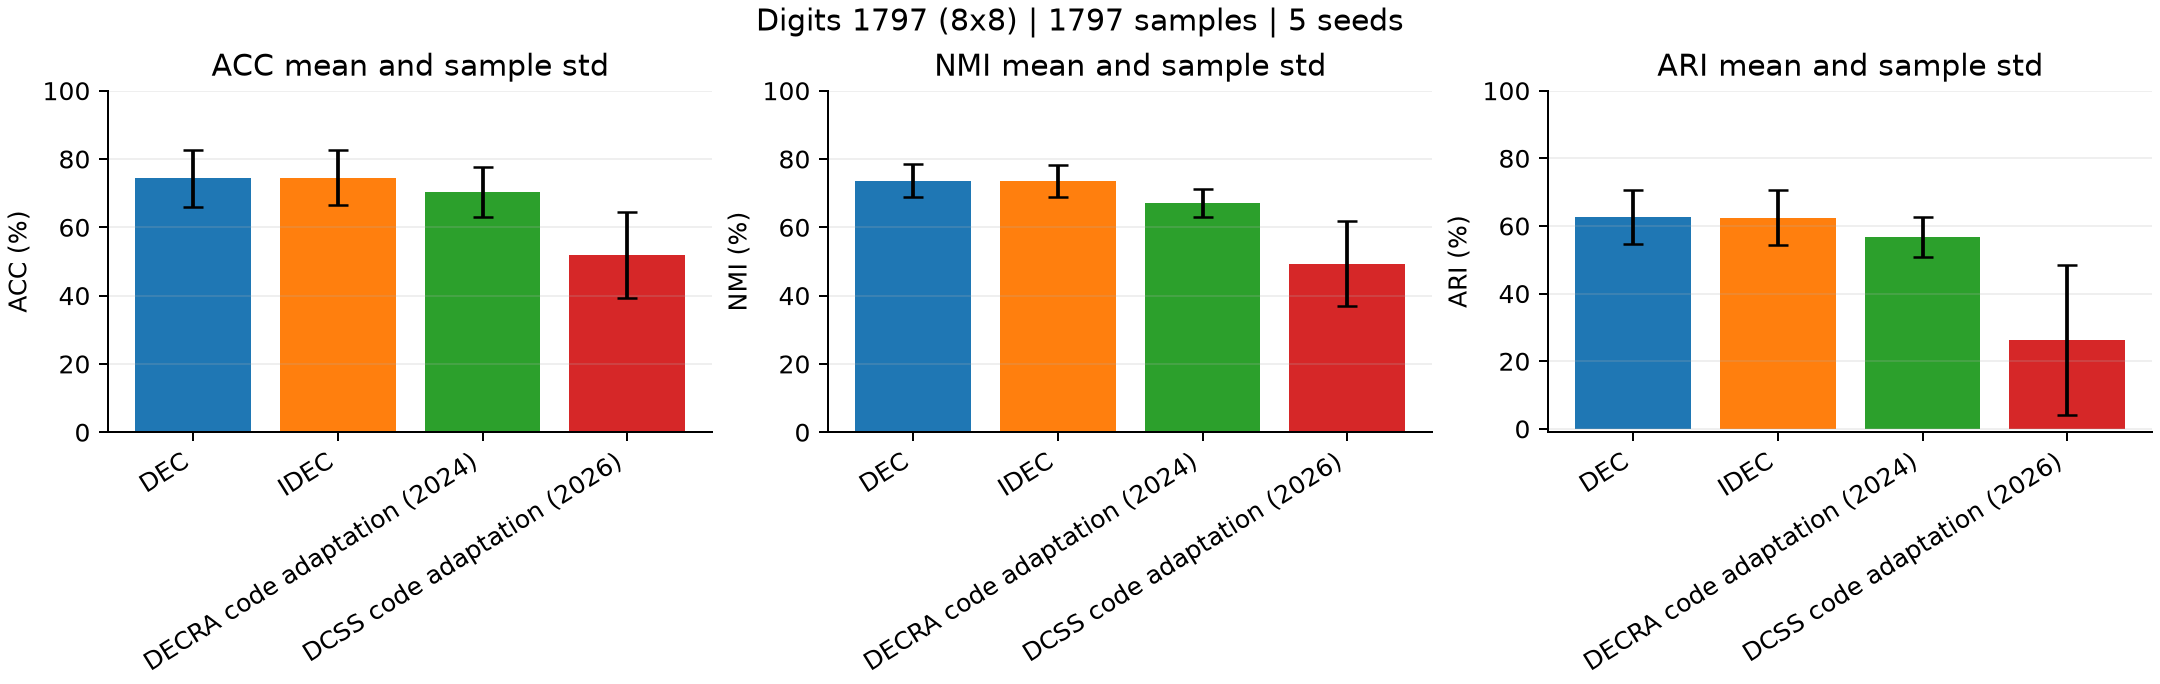

**Đọc kết quả:** IDEC có ACC trung bình cao nhất (74,50%). DEC có NMI cao nhất; DEC có ARI với nhãn cao nhất. Thứ hạng theo các độ đo không hoàn toàn giống nhau.

In [6]:
show_table(quality_table(summary))
show_table(pd.DataFrame([{
    'Phương pháp': r['method'],
    'ARI giữa seed': mean_std(r, 'pairwise_ari', scale=1, digits=4),
    'Thời gian (giây)': mean_std(r, 'standalone_seconds', scale=1),
    'Số cặp seed': int(r['n_pairs']),
} for _, r in summary.iterrows()]))
picture('performance.png')
best_acc = summary.loc[summary.acc_mean.idxmax()]
best_nmi = summary.loc[summary.nmi_mean.idxmax()]
best_ari = summary.loc[summary.ari_mean.idxmax()]
display(Markdown(f'**Đọc kết quả:** {best_acc.method} có ACC trung bình cao nhất '
                 f'({vn(best_acc.acc_mean*100)}%). {best_nmi.method} có NMI cao nhất; '
                 f'{best_ari.method} có ARI với nhãn cao nhất. Thứ hạng theo các độ đo không hoàn toàn giống nhau.'))

**Thời gian** tính chi phí nếu chạy riêng mỗi mô hình, gồm tiền huấn luyện, K-means, học cụm và ghi nhận loss;
không gồm chấm điểm cuối, vẽ hình, xuất tệp. Bốn phương pháp thực tế dùng chung tiền huấn luyện trong từng seed,
nên không cộng các dòng để tính tổng thời gian chiến dịch. Số giây chỉ phản ánh máy và cách đo hiện tại.

Mỗi phương pháp có 10 cặp seed. Các cặp dùng chung lượt chạy, không phải 10 quan sát độc lập để kiểm định thống kê.

## 5. IDEC có tốt hơn DEC một cách nhất quán không?

So sánh **cùng seed** giữ điểm khởi tạo giống nhau khi đổi phương pháp.
Dấu dương ở cột Δ nghĩa là IDEC cao hơn DEC. Cần đọc cả mức tăng và số seed có cải thiện.

Seed,DEC ACC (%),IDEC ACC (%),Δ IDEC − DEC (điểm %)
0,"79,86","79,41","-0,45"
1,"74,29","75,18","0,89"
2,"64,27","64,94","0,67"
3,"84,86","84,75","-0,11"
4,"68,34","68,22","-0,11"


IDEC cao hơn DEC ở **2/5 seed**. Chênh lệch trung bình: **0,1781 ± 0,5708 điểm phần trăm**. Đây là mô tả 5 cặp chạy, chưa chứng minh IDEC luôn tốt hơn hoặc có ưu thế có ý nghĩa thống kê.

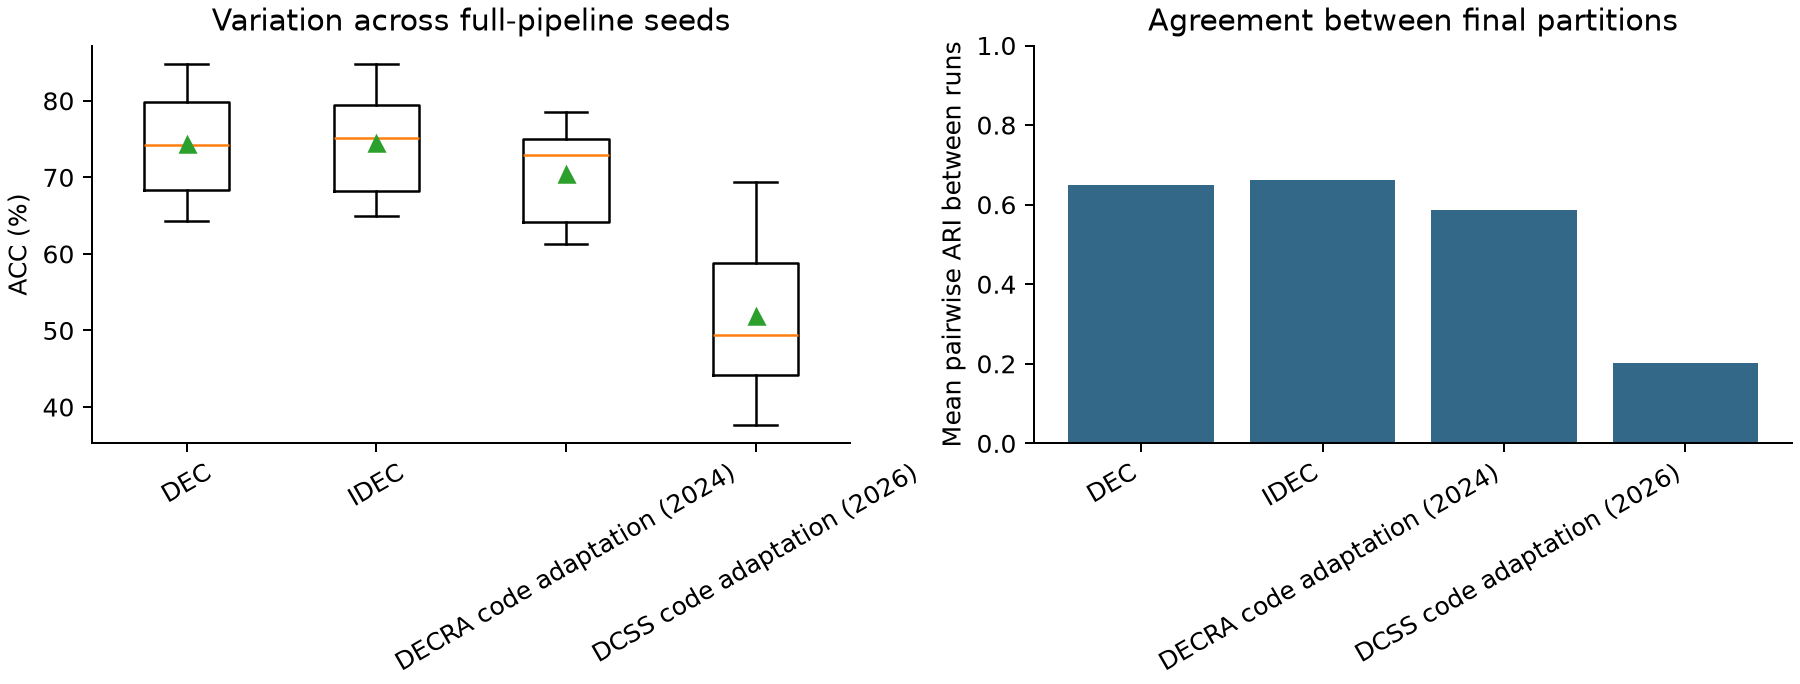

In [7]:
paired = runs.pivot(index='seed', columns='method', values='acc').sort_index() * 100
delta = paired['IDEC'] - paired['DEC']
show_table(pd.DataFrame({
    'Seed': paired.index,
    'DEC ACC (%)': [vn(v) for v in paired['DEC']],
    'IDEC ACC (%)': [vn(v) for v in paired['IDEC']],
    'Δ IDEC − DEC (điểm %)': [vn(v) for v in delta],
}))
display(Markdown(f'IDEC cao hơn DEC ở **{int((delta > 0).sum())}/{len(delta)} seed**. '
                 f'Chênh lệch trung bình: **{vn(delta.mean(), 4)} ± {vn(delta.std(ddof=1), 4)} điểm phần trăm**. '
                 'Đây là mô tả 5 cặp chạy, chưa chứng minh IDEC luôn tốt hơn hoặc có ưu thế có ý nghĩa thống kê.'))
picture('stability.png')

**Giải thích:** IDEC thêm lỗi tái tạo để hạn chế biến dạng biểu diễn. Trên Digits mức tăng ACC rất nhỏ,
chưa nhất quán giữa seed; DEC còn nhỉnh NMI và ARI. Nên nói **“IDEC nhỉnh hơn về ACC trong cấu hình này”**,
không nói **“IDEC tốt hơn ở mọi mặt”**.

DECRA có độ lệch chuẩn ACC nhỏ hơn nhưng điểm trung bình và ARI giữa seed cũng thấp hơn.
Chưa có cơ sở gọi DECRA ổn định hơn. Bản chuyển thể chưa dùng tiền huấn luyện residual riêng hoặc thử nghiệm nhiễu riêng.

## 6. DCSS có nhạy với độ rộng RBF không?

Mã DCSS gốc dùng kiến trúc khác; mạng chung ở đây có biểu diễn tuyến tính.
Nếu khoảng cách lớn so với σ=1, các điểm RBF đều nhỏ và xác suất gán cụm gần đều.
Đây là một giả thuyết giải thích kết quả thấp, chưa phải kết luận DCSS gốc kém.

Phép bổ sung khởi tạo σ theo **RMS**: căn trung bình khoảng cách bình phương trong từng cụm K-means ban đầu.
Chỉ dùng X và tâm, không dùng nhãn hay tìm kiếm theo ACC. Phép này được đề xuất sau khi thấy lượt chính,
nên phải ghi rõ là **đối chiếu bổ sung**, không thay kết quả chính.

In [8]:
ABLATION = ROOT / 'results/dcss_width_ablation_20261013'

def same_initial_models(first, second, seeds):
    for s in seeds:
        for stem in ['pretrain', 'initialization']:
            name = f'{stem}_seed{s}.npz'
            with np.load(first/'models'/name, allow_pickle=False) as a, np.load(second/'models'/name, allow_pickle=False) as b:
                if set(a.files) != set(b.files) or any(not np.array_equal(a[k], b[k]) for k in a.files):
                    return False
    return True

extra = None
if (ABLATION / 'verification.json').is_file():
    extra_config = json.loads((ABLATION / 'config.json').read_text(encoding='utf-8'))
    extra_check = json.loads((ABLATION / 'verification.json').read_text(encoding='utf-8'))
    common_keys = ['sha256_training_X', 'sha256_sample_indices', 'seeds', 'clusters', 'architecture',
                   'pretrain_epochs', 'cluster_epochs', 'batch_size', 'learning_rate',
                   'dcss_silhouette_weight', 'dcss_entropy_weight', 'dcss_temperature', 'dcss_distance_normalization']
    matched = (extra_check.get('status') == 'passed'
               and all(config[k] == extra_config[k] for k in common_keys)
               and same_initial_models(OUT, ABLATION, config['seeds']))
    if matched:
        extra = pd.read_csv(ABLATION / 'summary.csv')
        comparison = pd.concat([
            summary[summary.method == 'DCSS'].assign(configuration='σ = 1, lượt chính'),
            extra.assign(configuration='σ = RMS, bổ sung'),
        ], ignore_index=True)
        show_table(quality_table(comparison, name_column='configuration'))
        show_table(pd.DataFrame([{
            'Cấu hình': r['configuration'],
            'ARI giữa seed': mean_std(r, 'pairwise_ari', scale=1, digits=4),
            'Số cặp seed': int(r['n_pairs']),
        } for _, r in comparison.iterrows()]))
        increase = (extra.iloc[0].acc_mean - comparison.iloc[0].acc_mean) * 100
        display(Markdown(f'Khởi tạo theo dữ liệu tăng ACC trung bình **{vn(increase)} điểm phần trăm**. '
                         'Đã đối chiếu cùng dữ liệu, seed, trọng số và tâm ban đầu.'))
        diagnostic = json.loads((ROOT/'checks/dcss_width_diagnostics.json').read_text(encoding='utf-8'))
        diag = diagnostic['initialization_variants']['source_sigma_1']
        show_table(pd.DataFrame([
            ['Khoảng cách bình phương đến tâm gần nhất, trung vị', vn(diagnostic['nearest_center_squared_distance']['median'])],
            ['Điểm RBF cao nhất, trung vị', vn(diag['max_gaussian_activation']['median'], 5)],
            ['Xác suất cụm lớn nhất, trung bình', vn(diag['mean_max_assignment_probability'], 4)],
        ], columns=['Chẩn đoán không dùng nhãn ở seed 0', 'Giá trị']))
    else:
        print('Không ghép kết quả bổ sung cũ: dữ liệu, tham số hoặc khởi tạo chưa khớp lượt đang xem.')
else:
    print('Chưa có kết quả đối chiếu độ rộng được kiểm chứng.')

Phương pháp,Số seed,ACC (%),NMI (%),ARI (%)
"σ = 1, lượt chính",5,"51,89 ± 12,51","49,34 ± 12,37","26,23 ± 22,23"
"σ = RMS, bổ sung",5,"73,64 ± 8,00","71,22 ± 4,30","61,43 ± 7,08"


Cấu hình,ARI giữa seed,Số cặp seed
"σ = 1, lượt chính","0,2018 ± 0,1313",10
"σ = RMS, bổ sung","0,6541 ± 0,0575",10


Khởi tạo theo dữ liệu tăng ACC trung bình **21,76 điểm phần trăm**. Đã đối chiếu cùng dữ liệu, seed, trọng số và tâm ban đầu.

Chẩn đoán không dùng nhãn ở seed 0,Giá trị
"Khoảng cách bình phương đến tâm gần nhất, trung vị","7,21"
"Điểm RBF cao nhất, trung vị","0,00074"
"Xác suất cụm lớn nhất, trung bình","0,1068"


Trong bộ kết quả gốc, xác suất lớn nhất khoảng 0,1068, gần mức 0,1 của gán đều trên 10 cụm.
Đổi độ rộng giúp RBF phù hợp hơn với khoảng cách trong bản chuyển thể; chưa xác nhận nguyên nhân duy nhất
hoặc thứ hạng của DCSS gốc. Không dùng thời gian của hai chiến dịch để kết luận tăng tốc.
Cần xác nhận tiếp trên dữ liệu khác với quy tắc khởi tạo định trước.

## 7. Bài báo có bằng chứng phương pháp sau cải thiện không?

Có bằng chứng trong từng bài, nhưng phải giữ đúng dữ liệu, cách huấn luyện và loại sai số.
**Các bảng dưới do tác giả công bố, không phải kết quả Digits ở trên.**

### 7.1. DEC → IDEC: thêm tái tạo dữ liệu

Nguồn: [IDEC, IJCAI 2017, Table 2](https://www.ijcai.org/proceedings/2017/0243.pdf).
IDEC tăng ACC trên ba benchmark của bài. Bảng không cung cấp độ lệch chuẩn để kết luận ổn định giữa seed.

In [9]:
idec_rows = [('MNIST', 86.55, 88.06), ('USPS', 74.08, 76.05), ('REUTERS-10K', 73.68, 75.64)]
show_table(pd.DataFrame([
    [name, vn(before), vn(after), vn(after-before)] for name, before, after in idec_rows
], columns=['Benchmark trong bài IDEC', 'DEC ACC (%)', 'IDEC ACC (%)', 'Tăng (điểm %)']))

Benchmark trong bài IDEC,DEC ACC (%),IDEC ACC (%),Tăng (điểm %)
MNIST,"86,55","88,06","1,51"
USPS,"74,08","76,05","1,97"
REUTERS-10K,"73,68","75,64","1,96"


### 7.2. DECRA: thêm nhánh điều chỉnh biểu diễn

Nguồn: [DECRA Table 2 — ACC](https://link.springer.com/article/10.1007/s11063-024-11586-0/tables/2),
[Table 3 — NMI](https://link.springer.com/article/10.1007/s11063-024-11586-0/tables/3).
Trong bảng MNIST, DECRA có điểm cao hơn DEC/IDEC. Bài kết hợp baseline lấy từ tài liệu và code chạy lại,
chưa xác lập mọi hàng dùng đúng một quy trình. Bảng không hiện std/SE; phần đã đối chiếu chưa nêu số lần chạy.
NMI của bài dùng entropy lớn nhất, khác NMI trung bình số học của demo.

In [10]:
published_decra = json.loads((ROOT/'docs/references/decra_reported_results.json').read_text(encoding='utf-8'))
show_table(pd.DataFrame([
    [r['method'], vn(r['acc']*100, 1), vn(r['nmi']*100, 1)] for r in published_decra['rows']
], columns=['MNIST, theo bài DECRA', 'ACC (%)', 'NMI (%)']))
by_method = {r['method']:r for r in published_decra['rows']}
gain = (by_method['DECRA']['acc'] - by_method['IDEC']['acc']) * 100
display(Markdown(f'Trong bảng nguồn, DECRA hơn IDEC **{vn(gain, 1)} điểm ACC**. '
                 'Chưa chứng minh riêng nhánh thêm là nguyên nhân duy nhất; ở bản chuyển thể Digits lợi ích này chưa xuất hiện.'))

"MNIST, theo bài DECRA",ACC (%),NMI (%)
DEC,"84,7","79,1"
IDEC,"88,1","86,7"
DECRA,"96,4","91,7"


Trong bảng nguồn, DECRA hơn IDEC **8,3 điểm ACC**. Chưa chứng minh riêng nhánh thêm là nguyên nhân duy nhất; ở bản chuyển thể Digits lợi ích này chưa xuất hiện.

### 7.3. BRB: bổ sung reset và phân cụm lại

BRB điều chỉnh quá trình tối ưu để tránh bị giữ quá sớm quanh phân hoạch ban đầu.
Nguồn: [ICLR 2025, Table 13](https://proceedings.iclr.cc/paper_files/paper/2025/file/f91685b940d5032f0f0c247edbd72edd-Paper-Conference.pdf),
[mã tác giả](https://github.com/Probabilistic-and-Interactive-ML/breaking-the-reclustering-barrier).
Mỗi hàng so sánh IDEC có tiền huấn luyện với chính cấu hình đó cộng BRB: **10 seed, trung bình ± sai số chuẩn (SE)**.
SE khác độ lệch chuẩn của bảng Digits. OPTDIGITS trong bài khác bản Digits 1.797 mẫu ở đây.

In [11]:
context = json.loads((ROOT/'docs/literature_context.json').read_text(encoding='utf-8'))
brb_rows = context['brb_paper_reported']
show_table(pd.DataFrame([{
    'Benchmark': r['dataset'],
    'IDEC ACC (%), ±SE': f'{vn(r["baseline_mean"])} ± {vn(r["baseline_uncertainty"])}',
    'IDEC + BRB ACC (%), ±SE': f'{vn(r["variant_mean"])} ± {vn(r["variant_uncertainty"])}',
    'Tăng (điểm %)': vn(r['variant_mean'] - r['baseline_mean']),
} for r in brb_rows]))

Benchmark,"IDEC ACC (%), ±SE","IDEC + BRB ACC (%), ±SE",Tăng (điểm %)
MNIST,"93,16 ± 2,20","94,19 ± 2,20","1,03"
USPS,"81,59 ± 0,28","81,87 ± 0,14","0,28"
OPTDIGITS,"86,83 ± 0,21","87,35 ± 0,36","0,52"
Fashion-MNIST,"53,59 ± 1,01","55,96 ± 1,13","2,37"
KMNIST,"65,09 ± 1,03","65,61 ± 1,04","0,52"
GTSRB,"56,63 ± 2,16","62,84 ± 1,89","6,21"


**Cách diễn giải:** cơ chế mới hướng tới xử lý một hạn chế cụ thể. Số liệu nguồn hỗ trợ cải thiện
trong điều kiện tác giả báo cáo. Muốn quy cải thiện cho đúng thành phần thêm vào, cần đối chiếu
chỉ thay thành phần đó và giữ các điều kiện khác giống nhau.

[DCSS 2026](https://doi.org/10.1007/s10994-026-07026-w) báo cáo NMI/ARI trên benchmark riêng,
mean/std của 10 lượt; chưa có bảng ACC trên cùng bản Digits để đối chiếu trực tiếp.
**Không ghép điểm DEC 2016, IDEC 2017, DECRA 2024 và BRB 2025 thành một đường tăng ACC:**
ngay cả baseline MNIST giữa các bài cũng khác nhau.

## 8. Khảo sát hiện có bao nhiêu bài?

Số công trình khác số lượt chạy. Có mã công khai khác với đã chạy môi trường tác giả;
có tên benchmark khác với đã tải đủ dữ liệu.
Q chỉ áp dụng cho tạp chí, theo **SCImago SJR best quartile năm tham chiếu 2024**;
năm này có thể khác năm xuất bản, không phải phân hạng mới nhất 2026.

In [12]:
from scripts.summarize_survey import summarize
tracker = pd.read_csv(ROOT/'data/paper_tracker.csv', dtype=str).fillna('')
counts = summarize(tracker.to_dict(orient='records'))
show_table(pd.DataFrame([
    ['Công trình trong danh mục', counts['total_papers_in_tracker']],
    ['Bài phương pháp / bài tổng quan', f'{counts["paper_kinds"]["method"]} / {counts["paper_kinds"]["survey"]}'],
    ['Hội nghị / tạp chí', f'{counts["publication_types"]["conference"]} / {counts["publication_types"]["journal"]}'],
    ['Công trình từ 2023', counts['papers_from_2023_onward']],
    ['Bài phương pháp có mã công khai', counts['public_code_method_papers']],
    ['Bài tổng quan có thư viện/tài nguyên', counts['public_resources_survey_papers']],
    ['Phiếu đọc toàn văn hoàn tất', counts['full_text_reviews_completed']],
    ['Tóm tắt số liệu có nguồn', counts['paper_reported_numeric_summaries']],
    ['Bài còn thiếu trích xuất số liệu', len(counts['paper_result_extraction_pending'])],
    ['Môi trường mã tác giả đã chạy', counts['original_code_smoke_tested']],
    ['Tên/phạm vi benchmark đã đối chiếu', counts['dataset_scope_verified']],
], columns=['Nội dung', 'Số lượng']))
show_table(pd.DataFrame([
    [q, counts['journal_quartiles'][q]] for q in ['Q1','Q2','Q3','Q4']
] + [['Chưa xác minh đủ nguồn chính', counts['journal_quartile_unknown']]],
    columns=['Phân hạng tham chiếu trên bài tạp chí', 'Số bài']))
journal_rows = []
for r in tracker[tracker.publication_type == 'journal'].to_dict(orient='records'):
    q = r['quartile'] if r['quartile_verified'] == 'yes' else 'Chưa xác minh'
    journal_rows.append([r['method'], r['year'], r['venue'], q, r['ranking_year']])
show_table(pd.DataFrame(journal_rows, columns=['Công trình','Năm bài','Tạp chí','Q tham chiếu','Năm SJR']))

Nội dung,Số lượng
Công trình trong danh mục,32
Bài phương pháp / bài tổng quan,31 / 1
Hội nghị / tạp chí,27 / 5
Công trình từ 2023,16
Bài phương pháp có mã công khai,31
Bài tổng quan có thư viện/tài nguyên,1
Phiếu đọc toàn văn hoàn tất,2
Tóm tắt số liệu có nguồn,18
Bài còn thiếu trích xuất số liệu,13
Môi trường mã tác giả đã chạy,0


Phân hạng tham chiếu trên bài tạp chí,Số bài
Q1,3
Q2,1
Q3,0
Q4,0
Chưa xác minh đủ nguồn chính,1


Công trình,Năm bài,Tạp chí,Q tham chiếu,Năm SJR
DECRA,2024,Neural Processing Letters,Q2,2024
ProPos,2023,IEEE Transactions on Pattern Analysis and Machine Intelligence,Q1,2024
DCSS,2026,Machine Learning,Chưa xác minh,2024
DKM,2020,Pattern Recognition Letters,Q1,2024
Survey-ACM,2025,ACM Computing Surveys,Q1,2024


Nguồn: [danh mục công trình](../data/paper_tracker.csv), [bằng chứng Q](../docs/references/journal_rankings.json),
[liên kết paper, mã và dữ liệu](../docs/paper_download_links.md).
Q lấy từ nội dung chính chủ SCImago được lập chỉ mục; truy cập trực tiếp trong đợt tra cứu bị hạn chế.
Machine Learning còn thiếu bằng chứng phù hợp nên giữ riêng. PRLetters best quartile Q1 năm 2024
nhưng riêng ngành AI là Q2; không trộn hai cách tính.

**32 công trình đã lập danh mục không có nghĩa 32 bài đã đọc toàn văn.**
18 tóm tắt số liệu có thể từ bảng, abstract hoặc README, không phải 18 bài đã tái hiện.
Danh mục ưu tiên mã công khai nên tỷ lệ có mã không đại diện toàn lĩnh vực.

## 9. Hướng trình bày trong 7–10 phút

| Phần | Nội dung nói | Bằng chứng mở |
|---|---|---|
| Bài toán | Đo chất lượng và độ ổn định, không chọn chỉ theo năm công bố | Câu hỏi đầu notebook |
| Khảo sát | 32 công trình, 27 hội nghị, 5 tạp chí; Q và mức đọc/trích xuất tính riêng | Mục 8 |
| Tiến trình | DEC tự làm sắc; IDEC tái tạo; DECRA điều chỉnh biểu diễn; DCSS hình học cụm | Mục 2, nguồn bài |
| So sánh | Cùng Digits, khởi tạo theo seed và ngân sách học; 20 lượt | Mục 1 |
| Kết quả | ACC/NMI/ARI, biến động, đồng thuận phân hoạch và thời gian | Mục 4–5 |
| Giải thích | IDEC gần DEC; DECRA chưa cải thiện; DCSS nhạy độ rộng | Mục 5–6 |
| Kết luận | Giới hạn, so với bài gốc, kế hoạch mở rộng | Mục 7 và kết luận |

Mỗi phương pháp dùng một mạch: **hạn chế trước → thay đổi cơ chế → kỳ vọng → số liệu → giới hạn**.
Khi nói cải thiện, nêu rõ tăng bao nhiêu **điểm phần trăm**, trên dữ liệu nào, bao nhiêu lần chạy và loại sai số gì.
Không nói “ổn định nhất” chỉ từ một cột độ lệch chuẩn hoặc “tốt nhất 2026” chỉ từ một dataset.

In [13]:
local = summary.set_index('method')
conclusion = [
    ['IDEC so với DEC', f'ACC tăng {vn(delta.mean())} điểm; cao hơn {int((delta > 0).sum())}/{len(delta)} seed',
     'Thêm tái tạo có thể giữ cấu trúc; chưa thấy ưu thế nhất quán trên Digits'],
    ['DECRA so với IDEC', f'ACC {vn(local.loc["DECRA","acc_mean"]*100)}% so với {vn(local.loc["IDEC","acc_mean"]*100)}%',
     'Nhánh thêm chưa tạo lợi ích trong kiến trúc và ngân sách chung; không suy ra bài gốc kém'],
    ['DCSS ở lượt chính', f'ACC {mean_std(local.loc["DCSS"],"acc")}% ',
     'Điểm thấp và biến động; cần kiểm tra thang đo và khởi tạo RBF'],
]
if extra is not None:
    conclusion.append(['DCSS đổi độ rộng', f'ACC {mean_std(extra.iloc[0],"acc")}%',
                       'Có bằng chứng độ nhạy khởi tạo; phép bổ sung sau quan sát, chưa xác nhận thứ hạng toàn lĩnh vực'])
show_table(pd.DataFrame(conclusion, columns=['Đối chiếu','Số liệu tại máy này','Kết luận phù hợp']))

Đối chiếu,Số liệu tại máy này,Kết luận phù hợp
IDEC so với DEC,"ACC tăng 0,18 điểm; cao hơn 2/5 seed",Thêm tái tạo có thể giữ cấu trúc; chưa thấy ưu thế nhất quán trên Digits
DECRA so với IDEC,"ACC 70,40% so với 74,50%",Nhánh thêm chưa tạo lợi ích trong kiến trúc và ngân sách chung; không suy ra bài gốc kém
DCSS ở lượt chính,"ACC 51,89 ± 12,51%",Điểm thấp và biến động; cần kiểm tra thang đo và khởi tạo RBF
DCSS đổi độ rộng,"ACC 73,64 ± 8,00%","Có bằng chứng độ nhạy khởi tạo; phép bổ sung sau quan sát, chưa xác nhận thứ hạng toàn lĩnh vực"


**Kết luận:** IDEC có ACC trung bình cao nhất lượt chính nhưng chỉ hơn DEC rất ít; DEC nhỉnh NMI/ARI.
DECRA chưa cải thiện trong bản chuyển thể. DCSS cho thấy cần chú ý sự phù hợp giữa biểu diễn và độ rộng RBF.
Phương pháp ra đời sau có thêm cơ chế xử lý hạn chế cũ, nhưng lợi ích phải được kiểm chứng trong điều kiện cụ thể.

Chưa đủ bằng chứng chọn phương pháp mạnh nhất toàn lĩnh vực 2025–2026.
Bước tiếp theo là hoàn tất khảo sát toàn văn, thêm 2–3 dữ liệu, tăng seed và đối chiếu cấu hình gốc.
Xem [bài khảo sát đầy đủ](../docs/Bao_cao_timeline_20261013.html),
[hướng trình bày ngắn](../docs/Huong_trinh_bay_ket_qua.md).

## Phụ lục A. Toàn bộ 20 lượt chính

Dùng bảng này khi cần kiểm tra từng seed. Trình bày chính chỉ cần bảng tổng hợp và bảng ghép cặp.
Mã hash và nhật ký kỹ thuật được giữ ngoài phần trình bày.

In [14]:
show_table(pd.DataFrame([{
    'Phương pháp': r.method, 'Seed': int(r.seed),
    'ACC (%)': vn(r.acc*100), 'NMI (%)': vn(r.nmi*100), 'ARI (%)': vn(r.ari*100),
    'Thời gian (giây)': vn(r.standalone_seconds), 'Cụm có mẫu': int(r.nonempty_clusters),
} for r in runs.itertuples()]))
print(f'Đã kiểm tra {verification["runs_verified"]} lượt: cùng dữ liệu; tính lại nhãn từ trọng số và điểm từ dự đoán.')

Phương pháp,Seed,ACC (%),NMI (%),ARI (%),Thời gian (giây),Cụm có mẫu
DEC,0,"79,86","74,92","66,53","9,16",10
IDEC,0,"79,41","74,87","66,50","10,56",10
DECRA,0,"75,07","67,13","59,52","11,53",10
DCSS,0,"49,36","43,48","12,71","12,45",10
DEC,1,"74,29","74,70","62,89","7,24",10
IDEC,1,"75,18","75,57","64,07","7,31",10
DECRA,1,"72,95","70,75","60,56","9,83",10
DCSS,1,"69,45","65,81","55,80","9,77",10
DEC,2,"64,27","65,81","51,05","7,18",10
IDEC,2,"64,94","66,05","51,36","7,29",10


Đã kiểm tra 20 lượt: cùng dữ liệu; tính lại nhãn từ trọng số và điểm từ dự đoán.


## Phụ lục B. Chạy huấn luyện mới khi cần

Đổi `RUN_NEW_EXPERIMENT = True` để chạy lại với cấu hình đang xem; tạo và kiểm chứng kết quả trong thư mục mới.
`RUN_WIDTH_COMPARISON = True` chạy thêm đối chiếu độ rộng từ chính lượt mới đó. Mặc định cả hai biến tắt.
Sau khi chạy mới, notebook vẫn hiển thị bộ đã chọn ở đầu. Đổi `OUT` ở ô đầu sang thư mục vừa in ra,
rồi chạy lại các ô đọc kết quả. Nếu dùng đối chiếu mới, đổi `ABLATION` ở mục 6 cho đúng thư mục.
Thống kê khảo sát đọc trực tiếp danh mục; kết quả DCSS bổ sung chỉ được ghép khi điều kiện và khởi tạo khớp.

In [15]:
RUN_NEW_EXPERIMENT = False
RUN_WIDTH_COMPARISON = False
if RUN_NEW_EXPERIMENT:
    destination = ROOT/'results'/('timeline_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
    command = [sys.executable, '-B', str(ROOT/'run_demo.py'), '--data', str(data_path),
               '--methods', *METHODS, '--seeds', *map(str, config['seeds']), '--output', str(destination)]
    parameter_keys = ['clusters','latent_dim','pretrain_epochs','cluster_epochs','batch_size',
                      'learning_rate','gamma','target_interval','limit','decra_gamma',
                      'decra_reconstruction_weight','decra_consistency_weight','decra_kl_reduction',
                      'dcss_silhouette_weight','dcss_entropy_weight','dcss_temperature','dcss_distance_normalization']
    for key in parameter_keys:
        command += ['--'+key.replace('_','-'), str(config[key])]
    subprocess.run(command, cwd=ROOT, check=True)
    subprocess.run([sys.executable,'-B',str(ROOT/'checks/verify_experiment.py'),'--results',str(destination)], cwd=ROOT, check=True)
    subprocess.run([sys.executable,'-B',str(ROOT/'scripts/summarize_survey.py'),'--output',str(destination/'survey_counts.json')],
                   cwd=ROOT, check=True, capture_output=True, text=True)
    if RUN_WIDTH_COMPARISON:
        new_ablation = destination.parent/(destination.name+'_rbf')
        subprocess.run([sys.executable,'-B',str(ROOT/'scripts/run_dcss_calibration.py'),'--source',str(destination),'--output',str(new_ablation)], cwd=ROOT, check=True)
        subprocess.run([sys.executable,'-B',str(ROOT/'checks/verify_experiment.py'),'--results',str(new_ablation)], cwd=ROOT, check=True)
        print('Đối chiếu độ rộng mới:', new_ablation)
    print('Kết quả mới:', destination)
else:
    print('Chưa huấn luyện mới; notebook đang trình bày kết quả đã lưu.')

Chưa huấn luyện mới; notebook đang trình bày kết quả đã lưu.
